# **1. Project Overview**

This project presents a complete analysis of weekly retail sales using:

- Exploratory Data Analysis (EDA)

- Advanced feature engineering

- Statistical testing

- Predictive modeling (Linear Regression & Random Forest)

- Executive-level insights

The goal is to understand the drivers of weekly sales, identify seasonal and promotional patterns, and generate actionable recommendations for retail operations.

# **2. Data Loading and Preparation**

In [ ]:
#Import the libraries to be used
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 

sns.set(style = "whitegrid", palette = "deep")

#Load dataset
features = pd.read_csv('../data/features.csv')
sales = pd.read_csv('../data/sales.csv')
stores = pd.read_csv('../data/stores.csv')


In [ ]:
#Show the first 10 rows
features.head(10)

,store_id,date,temperature,fuel_price,markdown_1,markdown_2,markdown_3,markdown_4,markdown_5,cpi,unemployment,is_holiday,holiday_name,season
0,1,2022-01-01,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
1,1,2022-01-08,46.03,3.67,1356.75,2486.21,1427.01,983.27,2442.13,196.91,8.62,0,NaN,Winter
2,1,2022-01-15,25.96,5.46,3861.22,596.15,22.09,2854.11,3180.86,267.48,8.40,0,NaN,Winter
3,1,2022-01-22,25.92,3.58,579.35,2589.31,2493.19,1158.14,286.01,217.32,5.28,0,NaN,Winter
4,1,2022-01-29,78.37,4.41,4436.06,1416.64,478.38,2496.36,3423.53,247.35,8.40,0,NaN,Winter
5,1,2022-02-05,59.50,4.07,2137.71,76.26,431.57,110.00,2863.85,217.72,6.56,0,NaN,Winter
6,1,2022-02-12,92.61,3.25,2051.91,2266.65,915.19,269.43,1303.88,199.35,9.51,0,NaN,Winter
7,1,2022-02-19,84.65,4.40,4357.30,2411.02,746.28,3123.96,2427.04,276.89,9.27,0,NaN,Winter
8,1,2022-02-26,45.44,2.83,1139.68,1281.32,3272.06,3012.56,31.28,241.29,5.92,0,NaN,Winter
9,1,2022-03-05,37.77,2.86,1688.08,2828.73,1292.81,1815.77,3163.59,223.64,9.80,0,NaN,Spring


In [ ]:
sales.head(10)

,store_id,department,date,weekly_sales,is_holiday
0,1,1,2022-01-01,119075.96,1
1,1,2,2022-01-01,119107.85,1
2,1,3,2022-01-01,84369.88,1
3,1,4,2022-01-01,88445.24,1
4,1,5,2022-01-01,65159.85,1
5,1,6,2022-01-01,99015.94,1
6,1,7,2022-01-01,157858.77,1
7,1,8,2022-01-01,58702.96,1
8,1,9,2022-01-01,199677.02,1
9,1,10,2022-01-01,139744.34,1


In [ ]:
stores.head(10)

,store_id,store_type,store_size,region
0,1,A,213810,North
1,2,C,31639,East
2,3,B,102098,South
3,4,B,88289,North
4,5,A,218696,North
5,6,A,207397,West
6,7,A,134165,North
7,8,C,36140,South
8,9,B,100495,North
9,10,B,143563,South


In [ ]:
#Join datasets
df = sales.merge(stores, on="store_id")
df = df.merge(
    features,
    on=["store_id","date"],
    how="left"
)


df.head(10)

,store_id,department,date,weekly_sales,is_holiday_x,store_type,store_size,region,temperature,fuel_price,markdown_1,markdown_2,markdown_3,markdown_4,markdown_5,cpi,unemployment,is_holiday_y,holiday_name,season
0,1,1,2022-01-01,119075.96,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
1,1,2,2022-01-01,119107.85,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
2,1,3,2022-01-01,84369.88,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
3,1,4,2022-01-01,88445.24,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
4,1,5,2022-01-01,65159.85,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
5,1,6,2022-01-01,99015.94,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
6,1,7,2022-01-01,157858.77,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
7,1,8,2022-01-01,58702.96,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
8,1,9,2022-01-01,199677.02,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
9,1,10,2022-01-01,139744.34,1,A,213810,North,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156000 entries, 0 to 155999
Data columns (total 20 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   store_id      156000 non-null  int64  
 1   department    156000 non-null  int64  
 2   date          156000 non-null  object 
 3   weekly_sales  156000 non-null  float64
 4   is_holiday_x  156000 non-null  int64  
 5   store_type    156000 non-null  object 
 6   store_size    156000 non-null  int64  
 7   region        156000 non-null  object 
 8   temperature   156000 non-null  float64
 9   fuel_price    156000 non-null  float64
 10  markdown_1    156000 non-null  float64
 11  markdown_2    156000 non-null  float64
 12  markdown_3    156000 non-null  float64
 13  markdown_4    156000 non-null  float64
 14  markdown_5    156000 non-null  float64
 15  cpi           156000 non-null  float64
 16  unemployment  156000 non-null  float64
 17  is_holiday_y  156000 non-null  int64  
 18  holi

In [ ]:
#Cleaning categories
cat_cols = ['store_type', 'region', 'holiday_name', 'season']

for col in cat_cols:
        df[col] = (
            df[col]
            .astype(str)
            .str.strip()
            .str.lower()
        )
    
#Convert columns to date
df['date'] = pd.to_datetime(df['date'], errors = 'coerce')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156000 entries, 0 to 155999
Data columns (total 20 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   store_id      156000 non-null  int64         
 1   department    156000 non-null  int64         
 2   date          156000 non-null  datetime64[ns]
 3   weekly_sales  156000 non-null  float64       
 4   is_holiday_x  156000 non-null  int64         
 5   store_type    156000 non-null  object        
 6   store_size    156000 non-null  int64         
 7   region        156000 non-null  object        
 8   temperature   156000 non-null  float64       
 9   fuel_price    156000 non-null  float64       
 10  markdown_1    156000 non-null  float64       
 11  markdown_2    156000 non-null  float64       
 12  markdown_3    156000 non-null  float64       
 13  markdown_4    156000 non-null  float64       
 14  markdown_5    156000 non-null  float64       
 15  cpi           156

In [ ]:
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156000 entries, 0 to 155999
Data columns (total 22 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   store_id      156000 non-null  int64         
 1   department    156000 non-null  int64         
 2   date          156000 non-null  datetime64[ns]
 3   weekly_sales  156000 non-null  float64       
 4   is_holiday_x  156000 non-null  int64         
 5   store_type    156000 non-null  object        
 6   store_size    156000 non-null  int64         
 7   region        156000 non-null  object        
 8   temperature   156000 non-null  float64       
 9   fuel_price    156000 non-null  float64       
 10  markdown_1    156000 non-null  float64       
 11  markdown_2    156000 non-null  float64       
 12  markdown_3    156000 non-null  float64       
 13  markdown_4    156000 non-null  float64       
 14  markdown_5    156000 non-null  float64       
 15  cpi           156

In [ ]:
#Data exploration
df.describe()

,store_id,department,date,weekly_sales,is_holiday_x,store_size,temperature,fuel_price,markdown_1,markdown_2,markdown_3,markdown_4,markdown_5,cpi,unemployment,is_holiday_y,year,month
count,156000.000000,156000.0000,156000,156000.000000,156000.000000,156000.000000,156000.000000,156000.000000,156000.000000,156000.000000,156000.000000,156000.000000,156000.000000,156000.000000,156000.000000,156000.000000,156000.000000,156000.000000
mean,25.500000,10.5000,2023-06-27 11:59:59.999999744,56503.488802,0.115385,136626.440000,59.875755,3.986344,2831.840176,1708.091033,2295.922200,1982.042679,2561.790629,240.469559,6.485572,0.115385,2022.987179,6.525641
min,1.000000,1.0000,2022-01-01 00:00:00,819.660000,0.000000,31639.000000,20.020000,2.500000,0.180000,0.200000,1.010000,1.130000,0.140000,180.000000,3.000000,0.000000,2022.000000,1.000000
25%,13.000000,5.7500,2022-09-29 06:00:00,21255.962500,0.000000,91417.000000,39.942500,3.240000,1308.727500,787.155000,1095.917500,969.917500,1198.375000,211.027500,4.720000,0.000000,2022.000000,4.000000
50%,25.500000,10.5000,2023-06-27 12:00:00,43394.870000,0.000000,140736.500000,60.065000,3.970000,2652.495000,1612.570000,2174.595000,1862.980000,2417.900000,240.945000,6.490000,0.000000,2023.000000,7.000000
75%,38.000000,15.2500,2024-03-24 18:00:00,79604.107500,0.000000,179797.000000,79.910000,4.750000,4027.545000,2423.002500,3212.695000,2790.137500,3600.245000,270.445000,8.220000,0.000000,2024.000000,9.250000
max,50.000000,20.0000,2024-12-21 00:00:00,505958.730000,1.000000,218696.000000,99.970000,5.500000,10977.070000,6599.720000,8798.150000,7692.880000,9891.190000,299.990000,10.000000,1.000000,2024.000000,12.000000
std,14.430916,5.7663,NaN,46717.490663,0.319487,53081.473652,23.114765,0.864025,1977.833293,1187.621364,1579.278801,1351.446660,1769.691198,34.600848,2.014998,0.319487,0.816399,3.437080


# **3. Feature Engineering**

In [ ]:
# Time Features
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['week'] = df['date'].dt.isocalendar().week
df['season'] = df['date'].dt.month % 12 // 3 + 1

###Quarter
df['quarter'] = df['date'].dt.quarter
###Day of Week
df['day_of_week'] = df['date'].dt.dayofweek
###Season
df['season'] = df['date'].dt.month % 12 // 3 + 1

##Business Features
###Markdown Total
markdown_cols = ['markdown_1','markdown_2','markdown_3','markdown_4','markdown_5']
df['markdown_total'] = df[markdown_cols].sum(axis=1)
###Has Markdown
df['has_markdown'] = df['markdown_total'] > 0

###Store Size Category
df['store_size_category'] = pd.cut(
    df['store_size'],
    bins=[0, 50000, 150000, 300000],
    labels=['Small', 'Medium', 'Large']
)

###Holiday Type
df['holiday_type'] = df['holiday_name'].fillna('None')

##Growth Features
###Week-over-Week Growth (WoW)
df = df.sort_values('date')
df['WoW_growth'] = df['weekly_sales'].pct_change()

###Month-over-Month Growth (MoM)
df['MoM_growth'] = df.groupby(['store_id'])['weekly_sales'].pct_change(4)

###Year-over-Year Growth (YoY)
df['YoY_growth'] = df.groupby(['store_id'])['weekly_sales'].pct_change(52)


##Lag Features
###Lagged Sales
df['lagged_sales'] = df.groupby('store_id')['weekly_sales'].shift(1)

###Lagged Markdown
df['lagged_markdown'] = df.groupby('store_id')['markdown_total'].shift(1)

##Rolling Features
###Rolling Mean
df['rolling_mean_4'] = df.groupby('store_id')['weekly_sales'].rolling(4).mean().reset_index(0, drop=True)

###Rolling Std
df['rolling_std_4'] = df.groupby('store_id')['weekly_sales'].rolling(4).std().reset_index(0, drop=True)


# Markdown Features

# **4. Exploratory Data Analysis (EDA)**

## **4.1 Weekly Sales by Region**

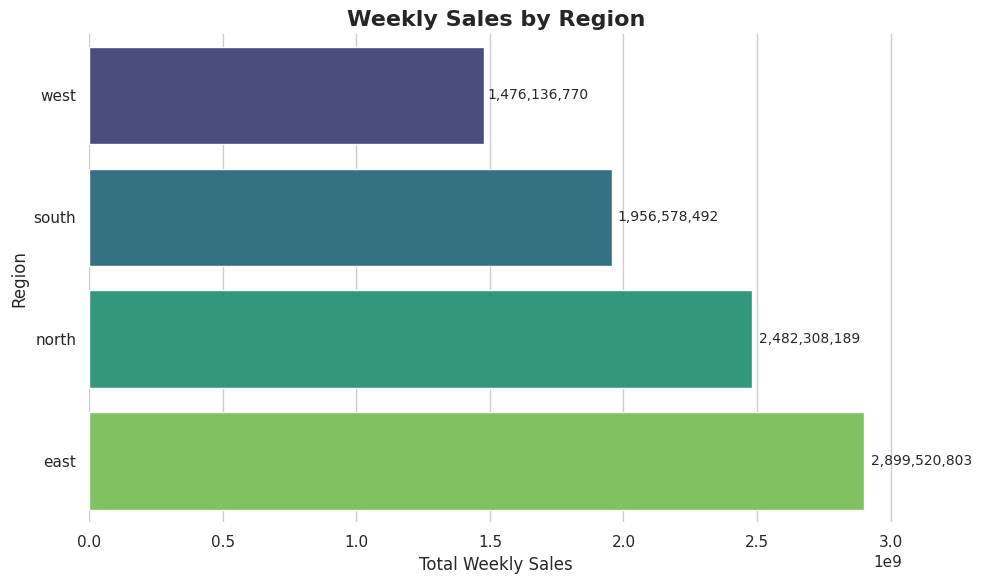

In [ ]:
sns.set_theme(style="whitegrid")

#Aggregated data
sales_by_region = df.groupby("region")["weekly_sales"].sum().sort_values()
plt.figure(figsize=(10, 6))
palette = sns.color_palette("viridis", len(sales_by_region))
ax = sns.barplot(
    x=sales_by_region.values,
    y=sales_by_region.index,
    hue=sales_by_region.index,
    palette=palette,
    dodge=False,
    legend=False
)
plt.title("Weekly Sales by Region", fontsize=16, weight="bold")
plt.xlabel("Total Weekly Sales")
plt.ylabel("Region")

for i, v in enumerate(sales_by_region.values):
    ax.text(v + (v * 0.01), i, f"{v:,.0f}", va="center", fontsize=10)

sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

## **4.2 Weekly Sales by Store**

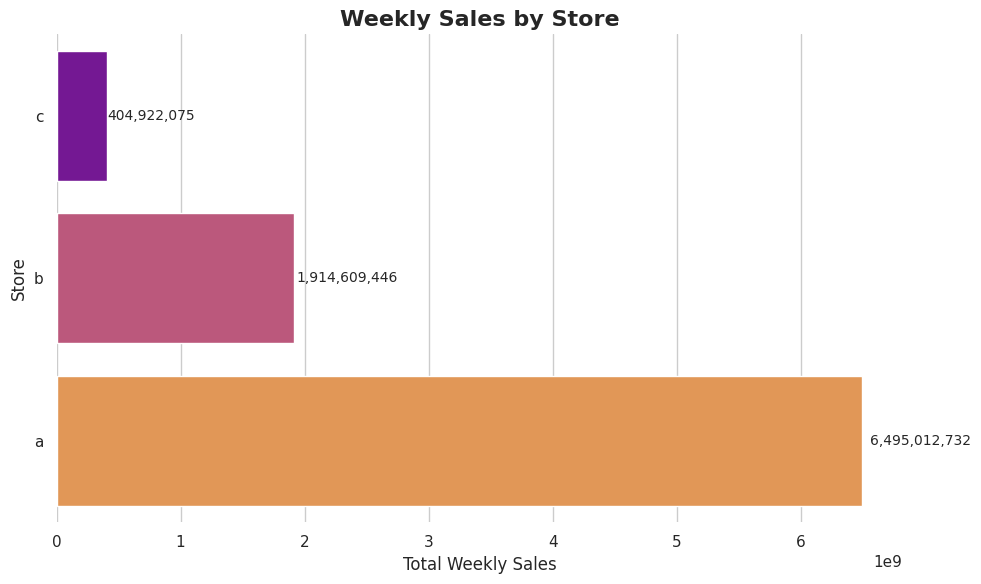

In [ ]:
sns.set_theme(style="whitegrid")

#Aggregated data
sales_by_store = df.groupby("store_type")["weekly_sales"].sum().sort_values()
plt.figure(figsize=(10, 6))
palette = sns.color_palette("plasma", len(sales_by_store))
ax = sns.barplot(
    x=sales_by_store.values,
    y=sales_by_store.index,
    hue=sales_by_store.index,
    palette=palette,
    dodge=False,
    legend=False
)
plt.title("Weekly Sales by Store", fontsize=16, weight="bold")
plt.xlabel("Total Weekly Sales")
plt.ylabel("Store")

for i, v in enumerate(sales_by_store.values):
    ax.text(v + (v * 0.01), i, f"{v:,.0f}", va="center", fontsize=10)

sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

## **4.3 Top 10 Departments**

/tmp/ipykernel_58/776581.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


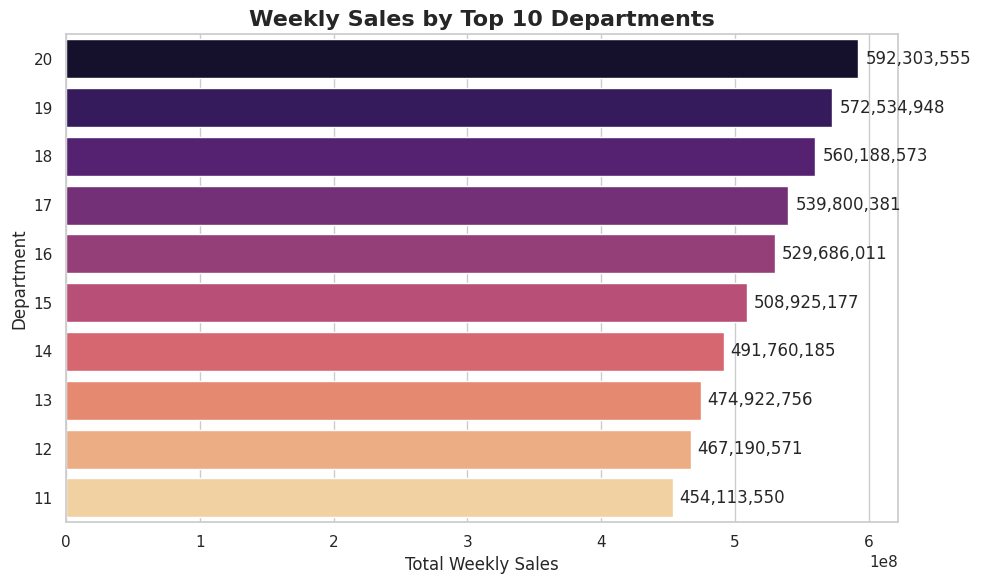

In [ ]:
sns.set_theme(style="whitegrid")

sales_by_department = (
    df.groupby("department")["weekly_sales"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10, 6))

palette = sns.color_palette(
    "magma",
    n_colors=len(sales_by_department)
)

ax = sns.barplot(
    x=sales_by_department.values,
    y=sales_by_department.index.astype(str),
    palette=palette
)

plt.title("Weekly Sales by Top 10 Departments",
          fontsize=16,
          weight="bold")

plt.xlabel("Total Weekly Sales")
plt.ylabel("Department")

for i, v in enumerate(sales_by_department.values):
    ax.text(
        v * 1.01,
        i,
        f"{v:,.0f}",
        va="center"
    )

plt.tight_layout()
plt.show()

## **4.4 Weekly Sales Over Time**

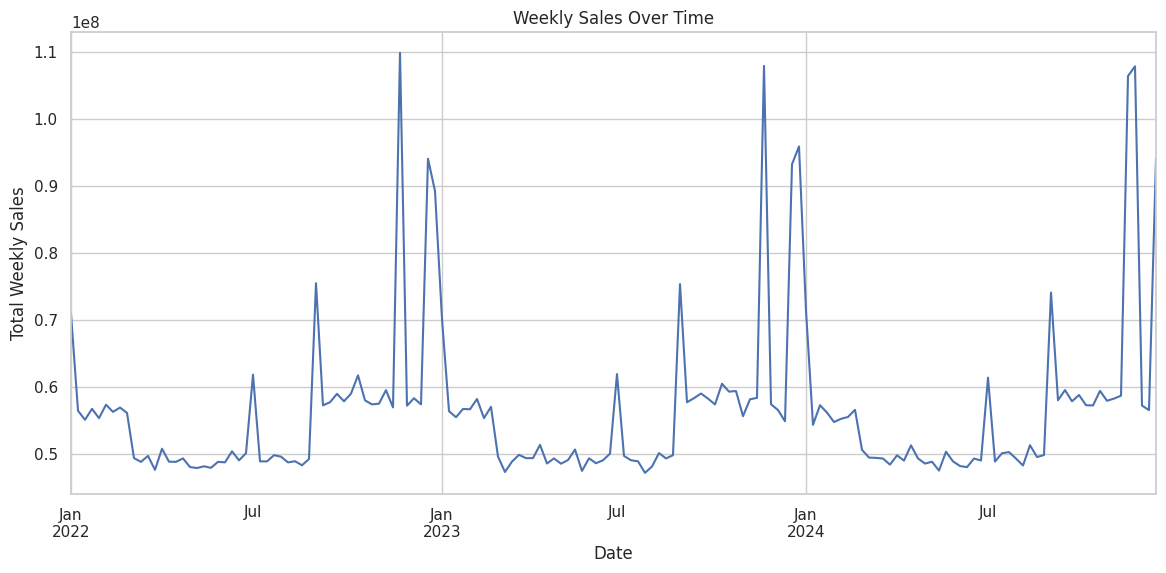

In [ ]:
#Weekly Sales Over Time
##Detect trends, spikes, drops, and seasonality.
plt.figure(figsize=(14,6))
df.groupby('date')['weekly_sales'].sum().plot()
plt.title('Weekly Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Total Weekly Sales')
plt.grid(True)
plt.show()

## **4.5 Sales Distribution**

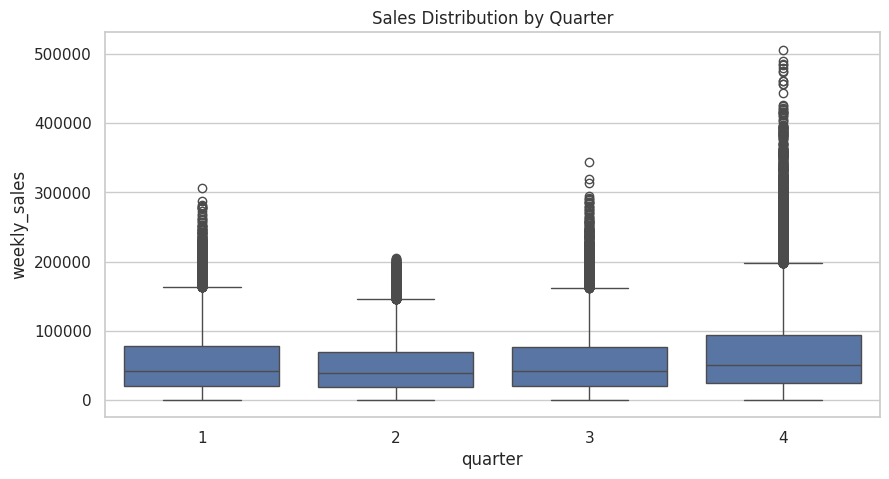

In [ ]:
#Sales by Season/Quarter
##See if there are peak seasons.
df['quarter'] = df['date'].dt.quarter

plt.figure(figsize=(10,5))
sns.boxplot(data=df, x='quarter', y='weekly_sales')
plt.title('Sales Distribution by Quarter')
plt.show()


## **4.6 Holiday vs Non-Holiday**

               count          mean     median           std
is_holiday_x                                               
0             138000  52852.575328  41406.465  41381.510831
1              18000  84493.825439  64985.855  70008.418493


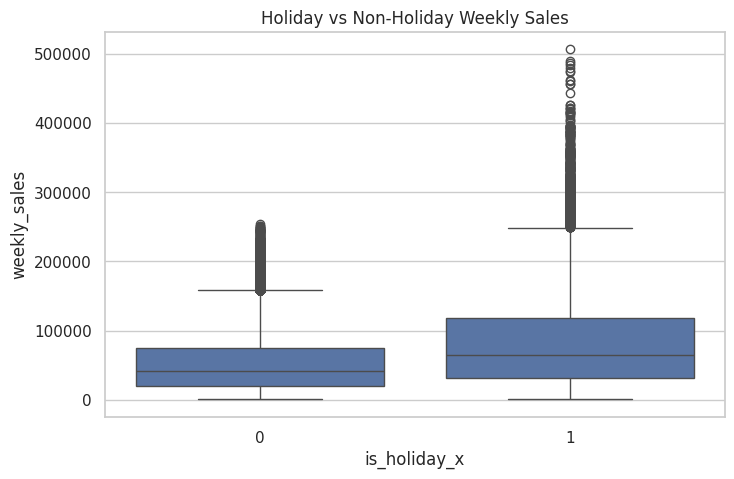

In [ ]:
#Holiday vs Non-Holiday Sales

holiday_sales_summary = (
    df.groupby("is_holiday_x")["weekly_sales"]
    .agg(["count", "mean", "median", "std"])
)

print(holiday_sales_summary)

##Measure impact of festivities.
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='is_holiday_x', y='weekly_sales')
plt.title('Holiday vs Non-Holiday Weekly Sales')
plt.show()

**Findings**

The average weekly sales during holiday weeks were compared with non-holiday weeks to evaluate the potential impact of seasonal events on retail performance.

The descriptive statistics indicate noticeable differences between both groups. To determine whether these differences are statistically significant, a two-sample t-test was conducted in the following section.

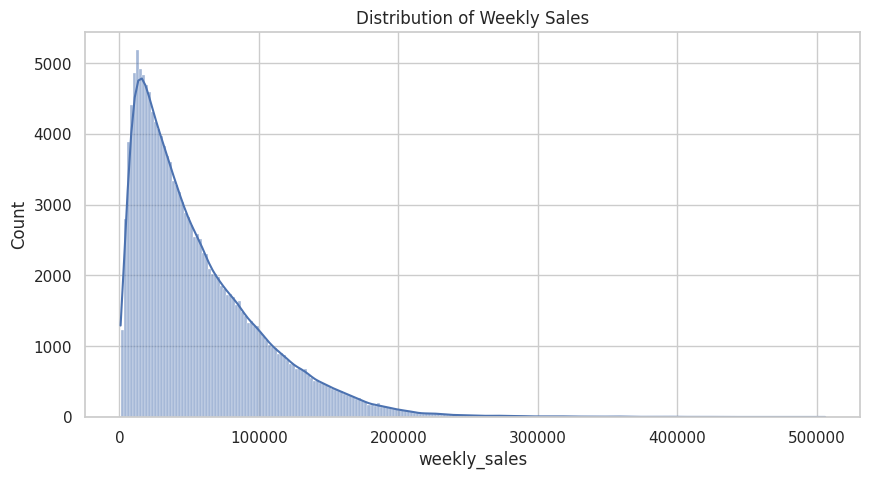

In [ ]:
#Histogram + KDE de Weekly Sales
##Understand the distribution (skew, tails, outliers).
plt.figure(figsize=(10,5))
sns.histplot(df['weekly_sales'], kde=True)
plt.title('Distribution of Weekly Sales')
plt.show()

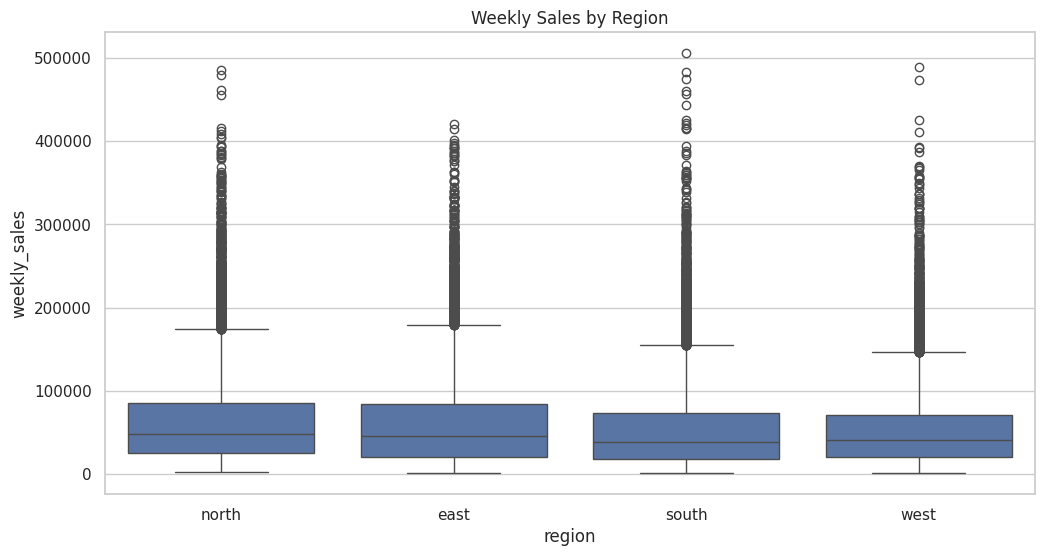

In [ ]:
#Boxplots by Region/Store Type
##Compare variability between groups.
plt.figure(figsize=(12,6))
sns.boxplot(data=df, x='region', y='weekly_sales')
plt.title('Weekly Sales by Region')
plt.show()


## **4.7 Markdown Impact**

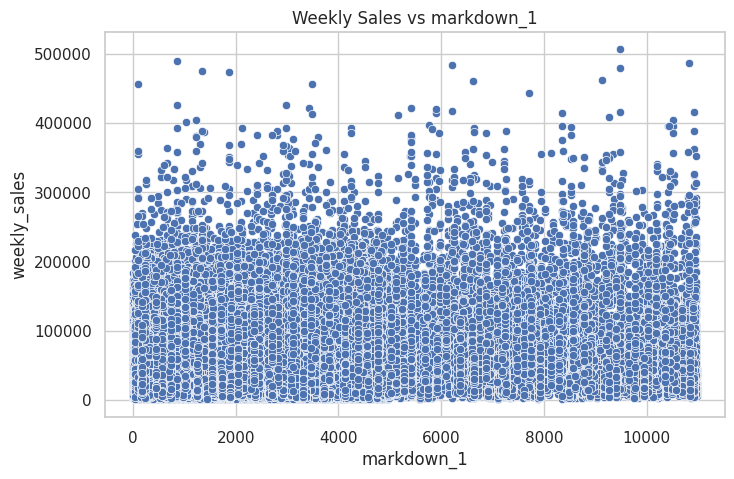

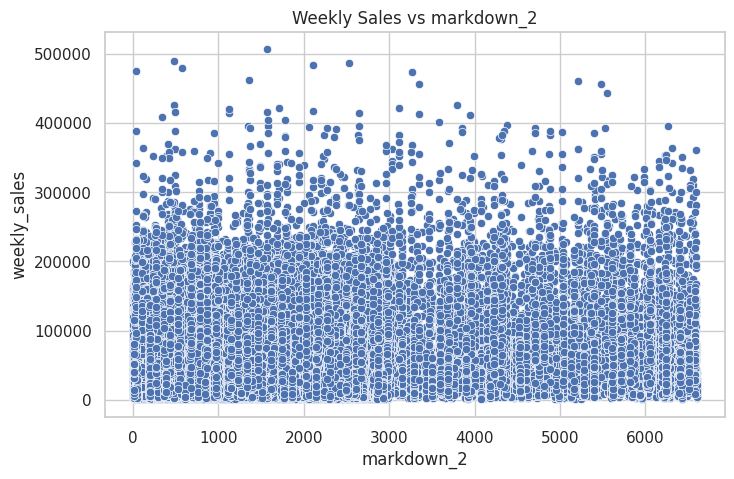

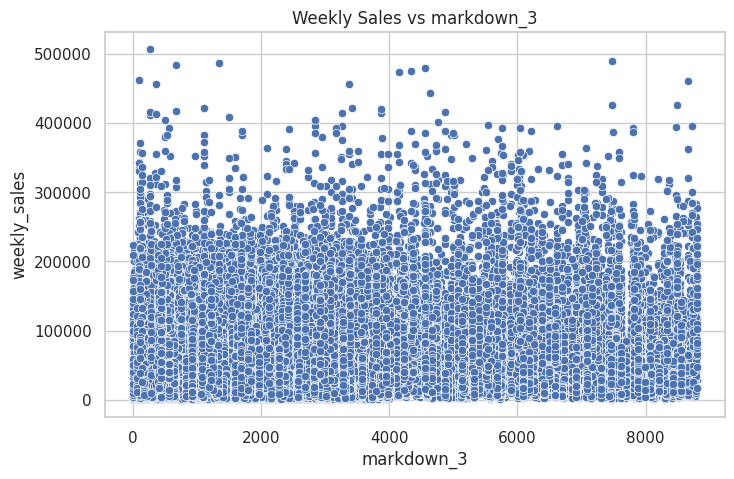

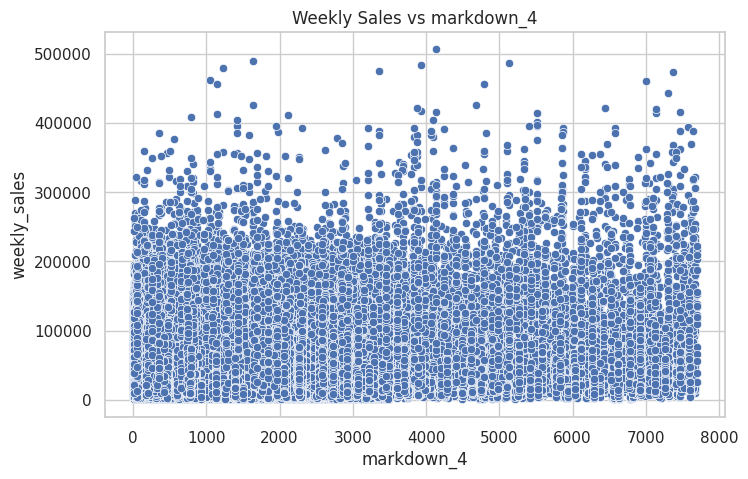

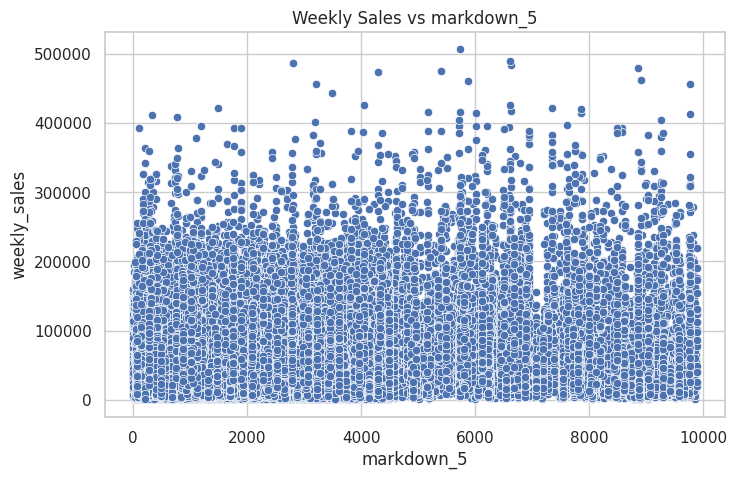

In [ ]:
#Scatterplots: Weekly Sales vs Markdown_1–5
##Visual relationship between markdowns and sales.
markdown_cols = ['markdown_1','markdown_2','markdown_3','markdown_4','markdown_5']

for col in markdown_cols:
    plt.figure(figsize=(8,5))
    sns.scatterplot(data=df, x=col, y='weekly_sales')
    plt.title(f'Weekly Sales vs {col}')
    plt.show()

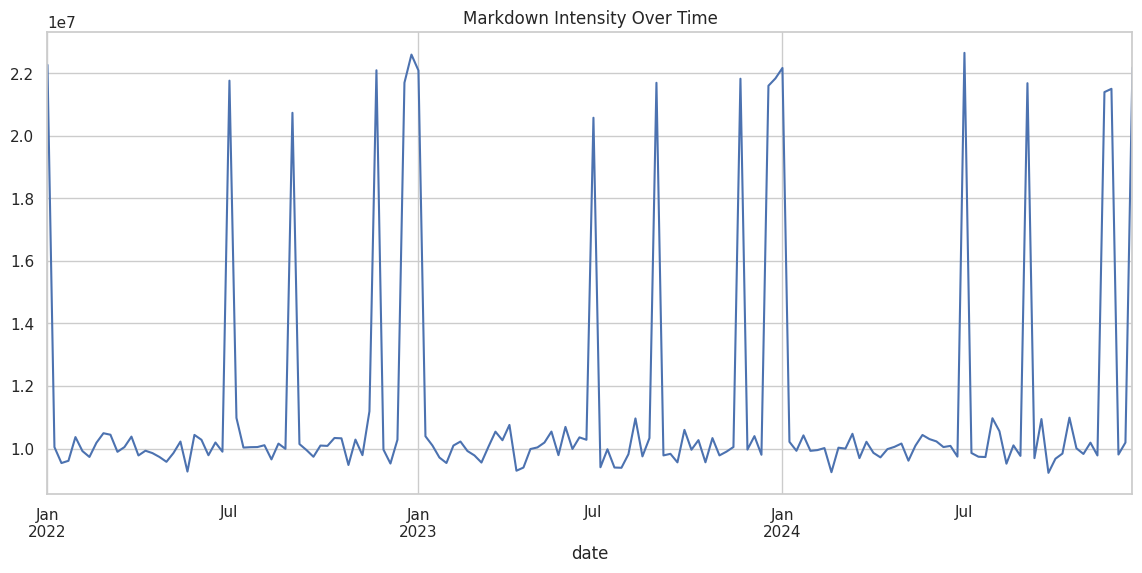

In [ ]:
#Markdown Intensity Over Time
##When the biggest discounts apply.
df['markdown_total'] = df[markdown_cols].sum(axis=1)

plt.figure(figsize=(14,6))
df.groupby('date')['markdown_total'].sum().plot()
plt.title('Markdown Intensity Over Time')
plt.show()


## **4.8 Pairplot**

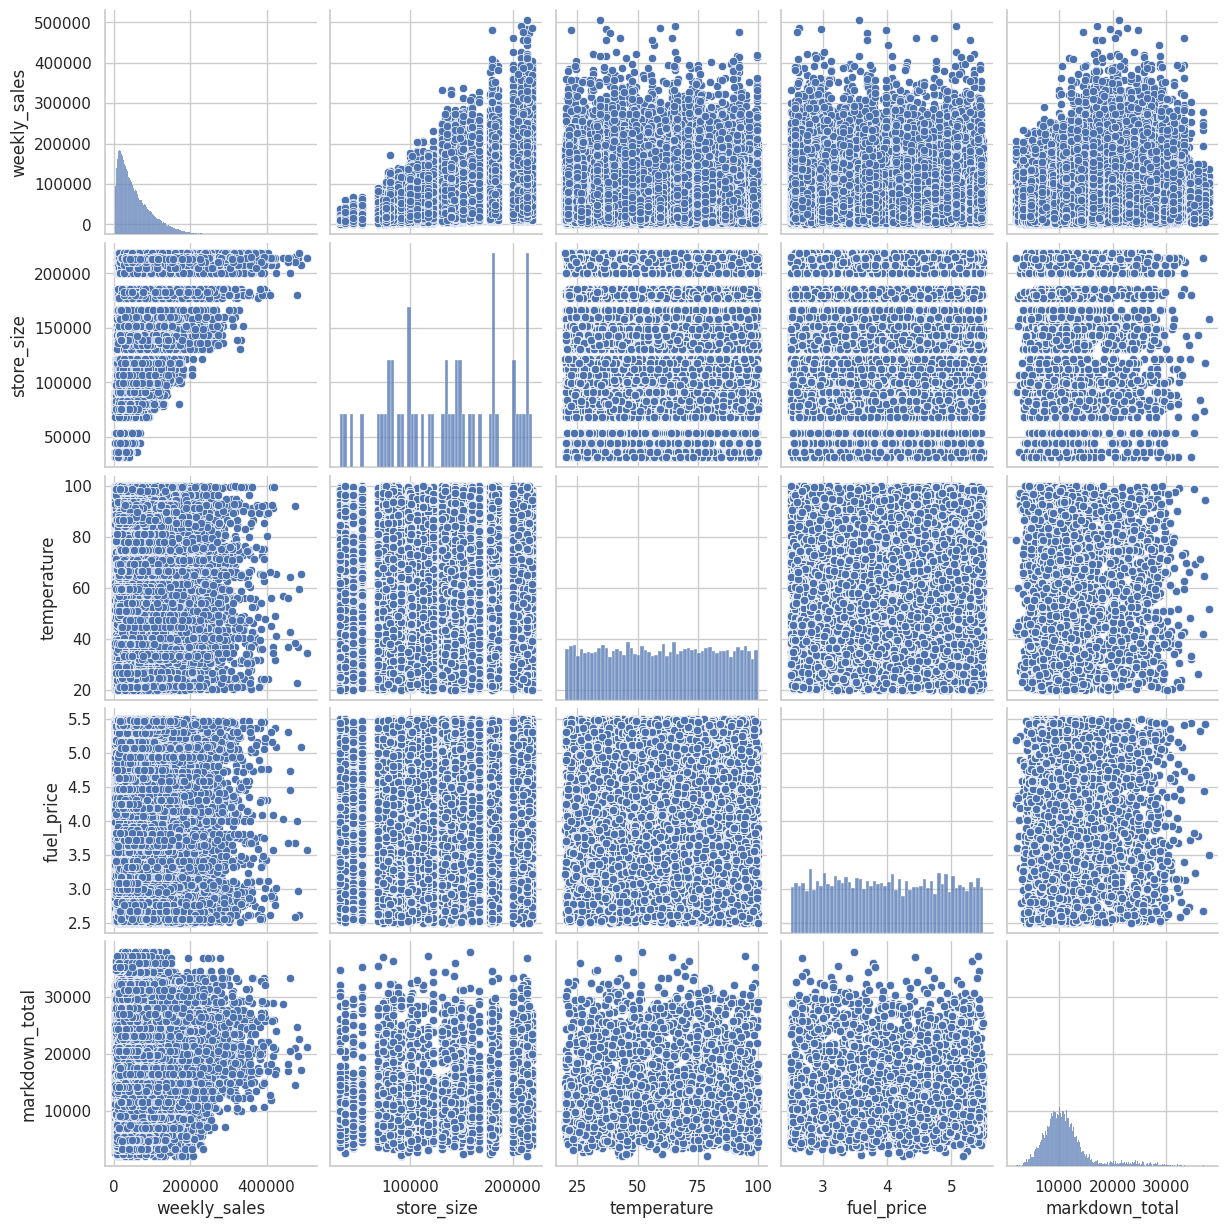

In [ ]:
#Pairplot
##View multiple relationships simultaneously.
sns.pairplot(df[['weekly_sales','store_size','temperature','fuel_price','markdown_total']])
plt.show()

## **4.9 Monthly Sales Heatmap**

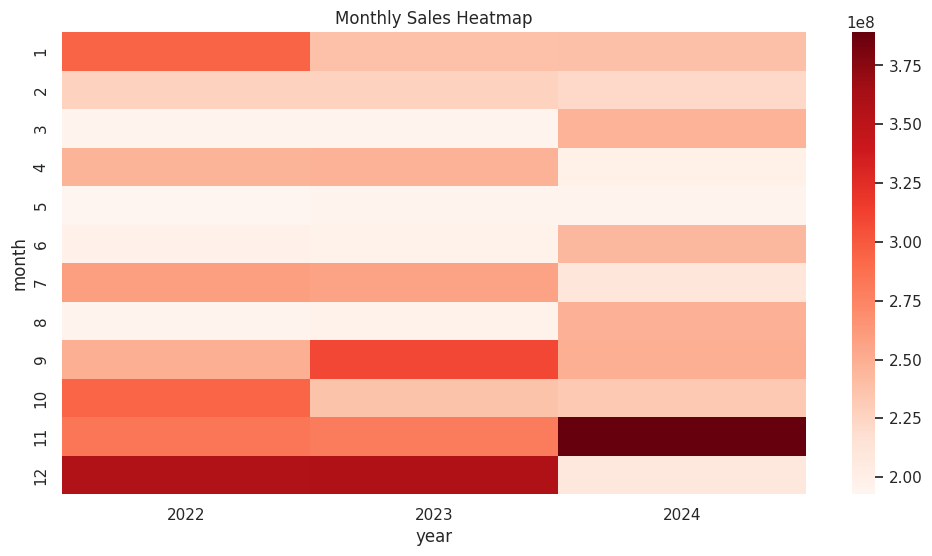

In [ ]:
#Heatmap Sales by Month
##Detect temporal patterns.

# Create pivot table
pivot = df.pivot_table(
    values='weekly_sales',
    index='month',
    columns='year',
    aggfunc='sum'
)

plt.figure(figsize=(12,6))
sns.heatmap(pivot, cmap='Reds', annot=False)
plt.title('Monthly Sales Heatmap')
plt.show()

# **5. Statistical Analysis**

## **5.1 Correlation Analysis**

To better understand the relationships among variables, a correlation matrix was computed.

Since the full matrix includes all engineered features and becomes visually large, only the most relevant correlations are displayed below.

This helps identify:

- Potential multicollinearity
- Strong relationships with weekly sales
- Variables that may be useful for predictive modeling

In [ ]:
corr_matrix = df[
[
"weekly_sales",
"markdown_1",
"markdown_2",
"markdown_3",
"markdown_4",
"markdown_5"
]
].corr()

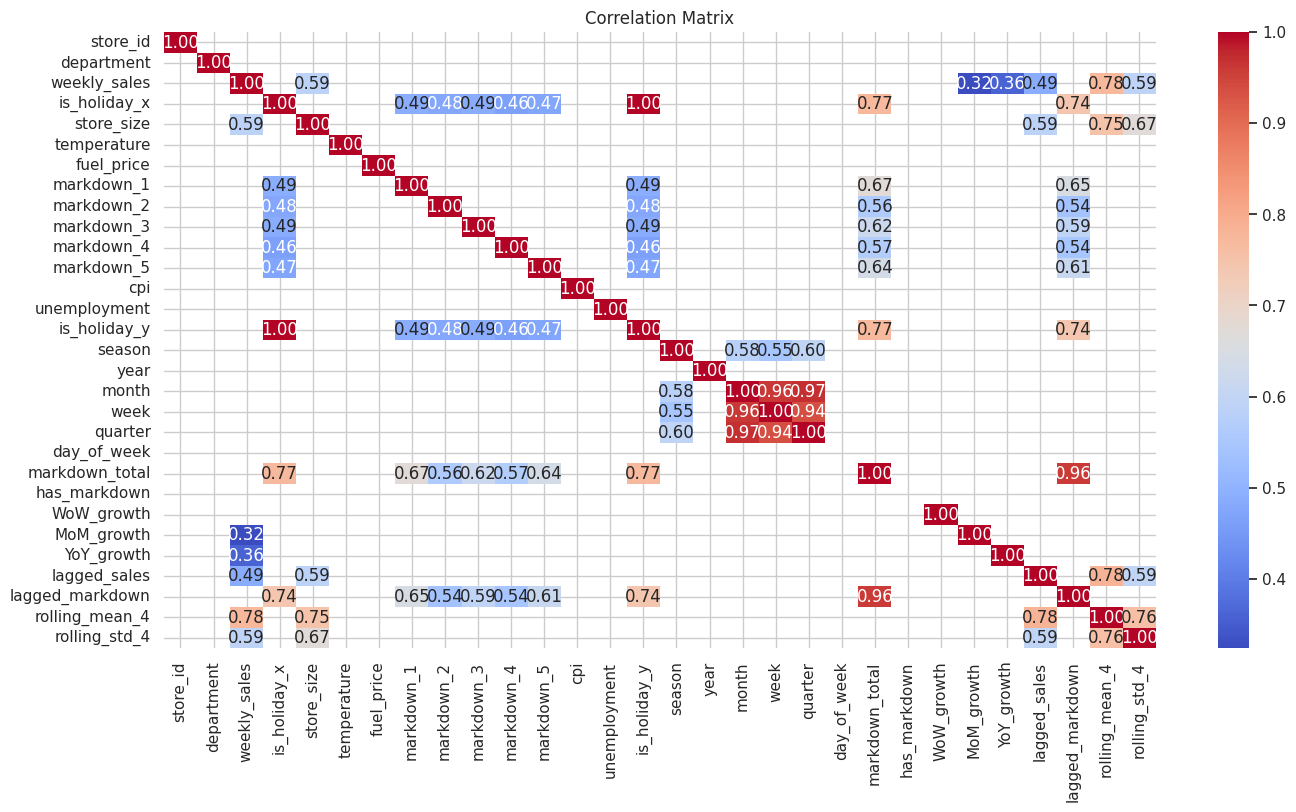

In [ ]:
corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(16, 8))

sns.heatmap(
    corr_matrix[(corr_matrix > 0.3) | (corr_matrix < -0.3)],
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

## **5.2 Descriptive Analysis**

In [ ]:
##Enables an understanding of the shape, dispersion, and behavior of the data.
df['weekly_sales'].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95])

count    156000.000000
mean      56503.488802
std       46717.490663
min         819.660000
25%       21255.962500
50%       43394.870000
75%       79604.107500
90%      120564.876000
95%      147776.141000
max      505958.730000
Name: weekly_sales, dtype: float64

## **5.3 IQR & Outliers**

In [ ]:
iqr = df['weekly_sales'].quantile(0.75) - df['weekly_sales'].quantile(0.25)
iqr


np.float64(58348.145000000004)

In [ ]:
#IQR Method
Q1 = df['weekly_sales'].quantile(0.25)
Q3 = df['weekly_sales'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['weekly_sales'] < lower_bound) | (df['weekly_sales'] > upper_bound)]
outliers.shape


(4489, 36)

## **5.4 T-test: Holiday vs Non-Holiday Sales**

In [ ]:
##Check whether holiday weeks actually have different sales figures.

from scipy.stats import ttest_ind

holiday_sales = df[df['is_holiday_x'] == True]['weekly_sales']
non_holiday_sales = df[df['is_holiday_x'] == False]['weekly_sales']

ttest_ind(holiday_sales, non_holiday_sales, equal_var=False)

TtestResult(statistic=np.float64(59.30106376613098), pvalue=np.float64(0.0), df=np.float64(19671.582137014993))

## **5.5 ANOVA: Sales by Region**

In [ ]:
##Check whether the regions have real differences in sales.

from scipy.stats import f_oneway

groups = [group['weekly_sales'].values for name, group in df.groupby('region')]
f_oneway(*groups)


F_onewayResult(statistic=np.float64(327.16184138810456), pvalue=np.float64(8.664833098256251e-212))

###### **5.6 Coefficient of variation by Region**

In [ ]:
##Measuring Risk and Variability

cv = df['weekly_sales'].std() / df['weekly_sales'].mean()
cv

df.groupby('region')['weekly_sales'].agg(['mean','std']).assign(cv=lambda x: x['std']/x['mean'])


,mean,std,cv
region,,,
east,58083.349419,47396.303412,0.816005
north,61200.892230,47696.246096,0.779339
south,52259.040905,46153.778658,0.883173
west,52568.973281,43928.260212,0.835631


# **6. Predictive Modeling**

## **6.1 Data Preparation**

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

# 1. Features Selection
features = [
    'store_size', 'markdown_total', 'lagged_sales', 'rolling_mean_4',
    'temperature', 'fuel_price', 'cpi', 'unemployment',
    'year', 'month', 'season'
]

X = df[features]
y = df['weekly_sales']

# 2. Train/Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. NaNs
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

## **6.2 Lineal Regression**

In [ ]:
lr = LinearRegression()
lr.fit(X_train_imputed, y_train)

y_pred_lr = lr.predict(X_test_imputed)

print("R2:", r2_score(y_test, y_pred_lr))
print("RMSE:", mean_squared_error(y_test, y_pred_lr)**0.5)

R2: 0.6394423443552105
RMSE: 28004.852798191645


## **6.3 Random Forest Regressor**

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    max_depth=12
)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("R2:", r2_score(y_test, y_pred_rf))
print("RMSE:", mean_squared_error(y_test, y_pred_rf)**0.5)


R2: 0.630324379818425
RMSE: 28356.74244484792


## **6.4 Comparison of models**

In [ ]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2': [r2_score(y_test, y_pred_lr), r2_score(y_test, y_pred_rf)],
    'RMSE': [
        mean_squared_error(y_test, y_pred_lr)**0.5,
        mean_squared_error(y_test, y_pred_rf)**0.5
    ]
})

results

,Model,R2,RMSE
0,Linear Regression,0.639442,28004.852798
1,Random Forest,0.630324,28356.742445


## **6.5 Feature Importance**

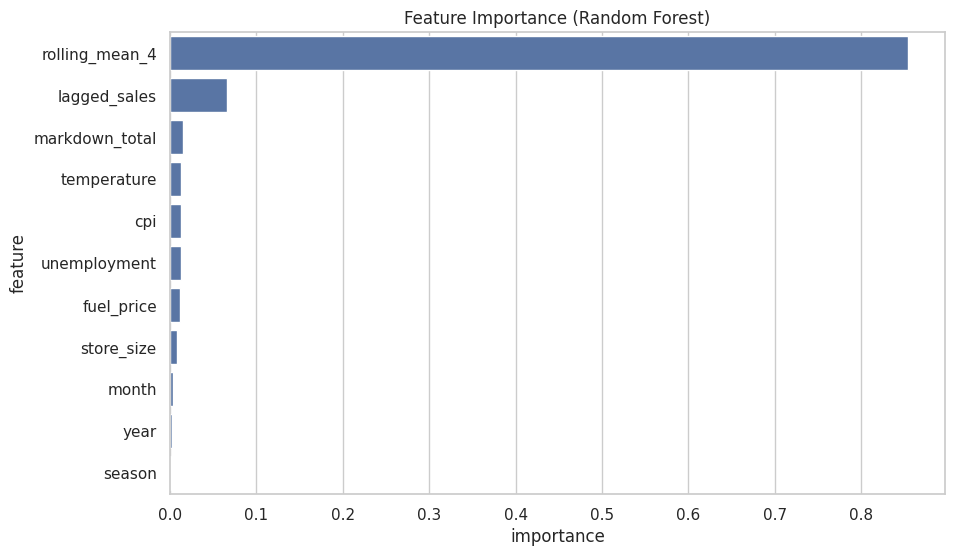

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

importances = rf.feature_importances_
feat_imp = pd.DataFrame({'feature': features, 'importance': importances})
feat_imp = feat_imp.sort_values('importance', ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(data=feat_imp, x='importance', y='feature')
plt.title('Feature Importance (Random Forest)')
plt.show()


# **7. Executive Insights**

## 📊 Sales Performance Overview

The retail business exhibits high sales variability, with an average weekly sales volume of $56,503 and a standard deviation of $46,717. The large gap between the median ($43,395) and the maximum value ($505,959) indicates a strongly right-skewed distribution driven by exceptionally high-performing weeks.

Additionally, the Interquartile Range (IQR) of $58,348 and the presence of 4,489 outlier observations suggest that sales performance is heavily influenced by special events, promotional campaigns, and seasonal demand spikes.

**Key Takeaway**

Sales patterns are not uniform throughout the year. A relatively small number of extraordinary weeks contribute disproportionately to total revenue.

## 🎉 Impact of Holiday Weeks

A two-sample T-test was conducted to compare holiday and non-holiday sales performance.

**Results:**

T-statistic = 59.30
P-value < 0.001

The results indicate a statistically significant difference between holiday and non-holiday weeks.

**Key Takeaway**

Holiday periods are strong sales drivers and should be considered strategic revenue-generating events. Planning inventory, staffing, and promotional activities around these periods can significantly improve business performance.

## 🌎 Regional Sales Differences

An ANOVA test was performed to evaluate sales performance across regions.

**Results:**

F-statistic = 327.16
P-value < 0.001

The analysis confirms statistically significant differences in sales performance among regions.

**Key Takeaway**

Regional characteristics play a critical role in retail performance. A single nationwide strategy may not be equally effective across all markets.

## 📈 Sales Variability by Region

The Coefficient of Variation (CV) was calculated to measure sales stability across regions.

**Key Takeaway**

The South region shows the highest sales volatility, while the North region demonstrates the most stable sales performance.

This suggests that forecasting, inventory management, and promotional strategies may need to be tailored differently for each region.

## 🔥 Impact of Promotional Markdowns

Correlation analysis and predictive modeling indicate that promotional markdowns positively influence weekly sales.

Markdown-related variables consistently appeared among the most relevant predictors of sales performance, suggesting that promotional strategies contribute significantly to revenue generation.

**Key Takeaway**

Promotions are effective sales drivers; however, their impact is not perfectly linear. Targeted and data-driven markdown strategies are likely to generate stronger returns than blanket discount campaigns.

## 🤖 Predictive Modeling Results

Two predictive models were developed and evaluated:

**Linear Regression**
R² =  0.639
RMSE = 28,005

**Random Forest Regressor**
R² =  0.630
RMSE = 28,357

The Linear Regression model slightly outperformed the Random Forest model in both explanatory power and prediction accuracy.

**Key Takeaway**

The results suggest that a substantial portion of weekly sales variability can be explained by the selected business and operational features. Both models captured approximately 63% of the variation in sales performance, indicating moderate predictive capability.

## 🎯 Key Drivers of Weekly Sales

Feature importance analysis identified the following variables as the strongest predictors of weekly sales:

Rolling 4-Week Average Sales (rolling_mean_4)
Previous Week Sales (lagged_sales)
Total Promotional Markdown (markdown_total)
Temperature
Consumer Price Index (CPI)

Internal business factors, especially historical sales trends and promotional activity, were more influential than external economic indicators.

**Key Takeaway**

Sales performance is largely driven by recent sales behavior and promotional decisions rather than macroeconomic conditions.


# **8. Conclusions**

- Weekly sales show high variability and strong seasonality.
- Holiday weeks significantly outperform non-holiday weeks.
- Regions differ statistically in performance.
- Linear Regression and Random Forest explain ~63% of sales variability.
- The most influential features are rolling_mean_4, lagged_sales, and markdown_total.

# **💼 Business Recommendations**

Based on the findings, the following actions are recommended:

- Develop region-specific sales and marketing strategies.
- Prioritize inventory planning during holiday periods.
- Leverage promotional markdowns strategically during low-demand periods.
- Focus forecasting efforts on historical sales patterns and recent trends.
- Allocate resources to high-performing stores and departments to maximize revenue opportunities.
- Monitor highly volatile regions more closely to reduce operational risk.

# **✅ Executive Summary**

This analysis revealed that weekly retail sales are strongly influenced by historical sales trends, promotional activity, seasonality, and regional differences. Holiday periods have a significant positive impact on performance, while regional variability suggests the need for localized business strategies. Predictive modeling demonstrated that sales can be reasonably forecasted using operational and promotional variables, with historical sales indicators emerging as the most influential predictors. These findings support data-driven decision-making for inventory planning, promotional optimization, and retail forecasting initiatives.